<a href="https://colab.research.google.com/github/devcodes28/AI-ML-Lab-24CSP503/blob/main/ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Data Loading and Initial Setup
We will download the Pima Indians Diabetes dataset directly from a reliable public mirror to ensure it runs seamlessly in Google Colab without requiring Kaggle API credentials.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

# Load dataset from public URL
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
column_names = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]
df = pd.read_csv(url, names=column_names)

# Quick view of the dataset
display(df.head())
print(f"Dataset Shape: {df.shape}")

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Dataset Shape: (768, 9)


# 2. Exploratory Data Analysis (EDA)
We will check the class distribution and inspect variables containing zero values that are biologically impossible (representing missing data).

/tmp/ipykernel_4771/3671189959.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Outcome', ax=axes[0], palette='viridis')


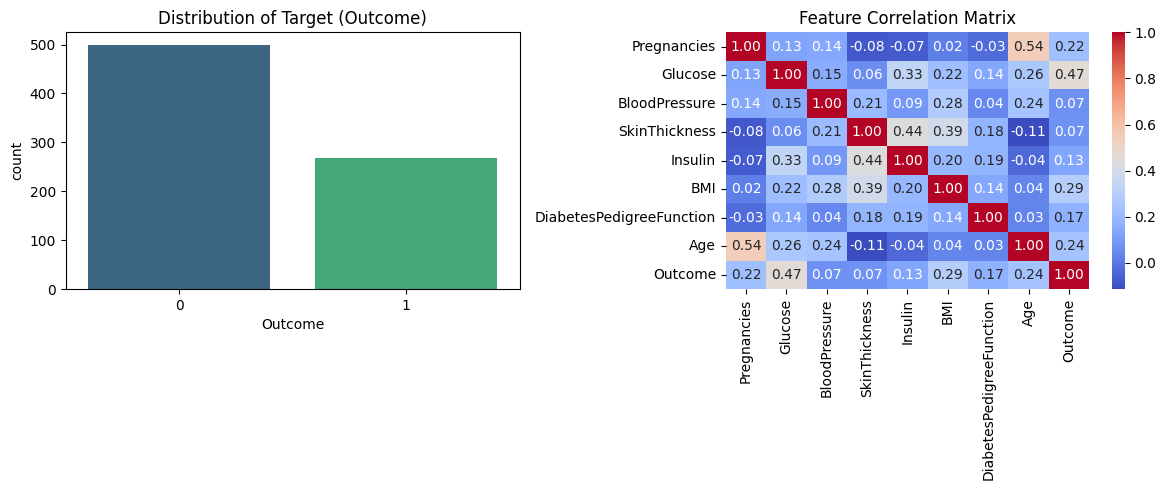

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Class Balance
sns.countplot(data=df, x='Outcome', ax=axes[0], palette='viridis')
axes[0].set_title('Distribution of Target (Outcome)')

# Correlations
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title('Feature Correlation Matrix')

plt.tight_layout()
plt.show()

# 3. Preprocessing (Missing Values, Outliers, Scaling, Split)
Certain features like `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` cannot physically be 0. We will treat these 0s as missing values and impute them with the median values of their respective target classes.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Replace 0 with NaN for relevant features
zero_features = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for col in zero_features:
    df[col] = df[col].replace(0, np.nan)

# Impute missing values with median grouped by target outcome
for col in zero_features:
    df[col] = df.groupby('Outcome')[col].transform(lambda x: x.fillna(x.median()))

# Split features and target
X = df.drop('Outcome', axis=1).values
y = df['Outcome'].values.reshape(-1, 1)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (614, 8)
X_test shape: (154, 8)


# 4. Custom ANN with Backpropagation
We will define our custom feedforward Neural Network class with 1 hidden layer, dynamic sigmoid activation, backpropagation vectorization, and binary cross-entropy loss.

In [ ]:
class CustomANN:
    def __init__(self, input_size, hidden_size, output_size=1, lr=0.01, seed=42):
        np.random.seed(seed)
        self.lr = lr
        # Initialize weights (He initialization for hidden, Xavier for output)
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(1.0 / hidden_size)
        self.b2 = np.zeros((1, output_size))

    def sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def sigmoid_derivative(self, a):
        return a * (1.0 - a)

    def forward(self, X):
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = self.sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = self.sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, output):
        m = X.shape[0]

        # Output layer error
        dz2 = output - y
        dW2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        # Hidden layer error
        da1 = np.dot(dz2, self.W2.T)
        dz1 = da1 * self.sigmoid_derivative(self.a1)
        dW1 = np.dot(X.T, dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        return dW1, db1, dW2, db2

    def update_params(self, dW1, db1, dW2, db2):
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2

    def compute_loss(self, y_pred, y_true):
        m = y_true.shape[0]
        epsilon = 1e-15
        y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
        loss = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
        return loss

# 5. Gradient Checking
To verify that the backpropagation analytical gradients match numerical gradients calculated using finite differences.

In [ ]:
def gradient_checking(ann, X, y, epsilon=1e-5):
    # Forward pass
    output = ann.forward(X)
    dW1, db1, dW2, db2 = ann.backward(X, y, output)

    # Flatten gradients
    grad_vector = np.concatenate([dW1.ravel(), db1.ravel(), dW2.ravel(), db2.ravel()])

    # Estimate gradients numerically
    num_grad = []
    params = [ann.W1, ann.b1, ann.W2, ann.b2]

    for param in params:
        flat_param = param.ravel()
        for i in range(len(flat_param)):
            original_val = flat_param[i]

            # J(theta + epsilon)
            flat_param[i] = original_val + epsilon
            loss_plus = ann.compute_loss(ann.forward(X), y)

            # J(theta - epsilon)
            flat_param[i] = original_val - epsilon
            loss_minus = ann.compute_loss(ann.forward(X), y)

            # Reset
            flat_param[i] = original_val

            # Compute numeric gradient
            grad_approx = (loss_plus - loss_minus) / (2.0 * epsilon)
            num_grad.append(grad_approx)

    num_grad_vector = np.array(num_grad)

    # Relative difference calculation
    numerator = np.linalg.norm(grad_vector - num_grad_vector)
    denominator = np.linalg.norm(grad_vector) + np.linalg.norm(num_grad_vector)
    difference = numerator / denominator

    print(f"Gradient check relative difference: {difference:.2e}")
    if difference < 1e-7:
        print("The backpropagation implementation is correct!")
    else:
        print("Potential implementation discrepancy in backprop.")

# Run gradient check on a small subset of features
check_ann = CustomANN(input_size=X_train.shape[1], hidden_size=4, lr=0.1)
gradient_checking(check_ann, X_train[:5], y_train[:5])

Gradient check relative difference: 1.91e-11
The backpropagation implementation is correct!


# 6. Model Training & Learning Curves
We will now train the custom Neural Network. We will print the training loss, test loss, and validation accuracy for target epochs, while tracking total execution duration.

In [ ]:
epochs = 1500
learning_rate = 0.1
hidden_units = 16

ann = CustomANN(input_size=X_train.shape[1], hidden_size=hidden_units, lr=learning_rate)

train_losses = []
test_losses = []

start_time = time.time()

for epoch in range(1, epochs + 1):
    # Forward and Backward passes on train dataset
    train_pred = ann.forward(X_train)
    dW1, db1, dW2, db2 = ann.backward(X_train, y_train, train_pred)
    ann.update_params(dW1, db1, dW2, db2)

    # Compute current epoch losses
    train_loss = ann.compute_loss(train_pred, y_train)
    test_pred = ann.forward(X_test)
    test_loss = ann.compute_loss(test_pred, y_test)

    train_losses.append(train_loss)
    test_losses.append(test_loss)

    # Print metrics every 150 epochs
    if epoch == 1 or epoch % 150 == 0:
        train_acc = np.mean((train_pred >= 0.5) == y_train) * 100
        test_acc = np.mean((test_pred >= 0.5) == y_test) * 100
        print(f"Epoch {epoch:04d}/{epochs} | Train Loss: {train_loss:.4f} | Test Loss: {test_loss:.4f} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")

training_time = time.time() - start_time
print(f"\nTraining completed in: {training_time:.4f} seconds")

Epoch 0001/1500 | Train Loss: 0.6753 | Test Loss: 0.6685 | Train Acc: 64.01% | Test Acc: 64.29%
Epoch 0150/1500 | Train Loss: 0.4782 | Test Loss: 0.5044 | Train Acc: 79.15% | Test Acc: 74.68%
Epoch 0300/1500 | Train Loss: 0.4249 | Test Loss: 0.4779 | Train Acc: 80.62% | Test Acc: 72.73%
Epoch 0450/1500 | Train Loss: 0.4091 | Test Loss: 0.4782 | Train Acc: 81.43% | Test Acc: 74.68%
Epoch 0600/1500 | Train Loss: 0.4025 | Test Loss: 0.4795 | Train Acc: 81.11% | Test Acc: 74.68%
Epoch 0750/1500 | Train Loss: 0.3981 | Test Loss: 0.4788 | Train Acc: 81.76% | Test Acc: 75.32%
Epoch 0900/1500 | Train Loss: 0.3944 | Test Loss: 0.4764 | Train Acc: 81.92% | Test Acc: 75.32%
Epoch 1050/1500 | Train Loss: 0.3909 | Test Loss: 0.4729 | Train Acc: 82.57% | Test Acc: 75.32%
Epoch 1200/1500 | Train Loss: 0.3874 | Test Loss: 0.4686 | Train Acc: 82.57% | Test Acc: 75.32%
Epoch 1350/1500 | Train Loss: 0.3839 | Test Loss: 0.4638 | Train Acc: 83.06% | Test Acc: 75.97%
Epoch 1500/1500 | Train Loss: 0.3804 | T

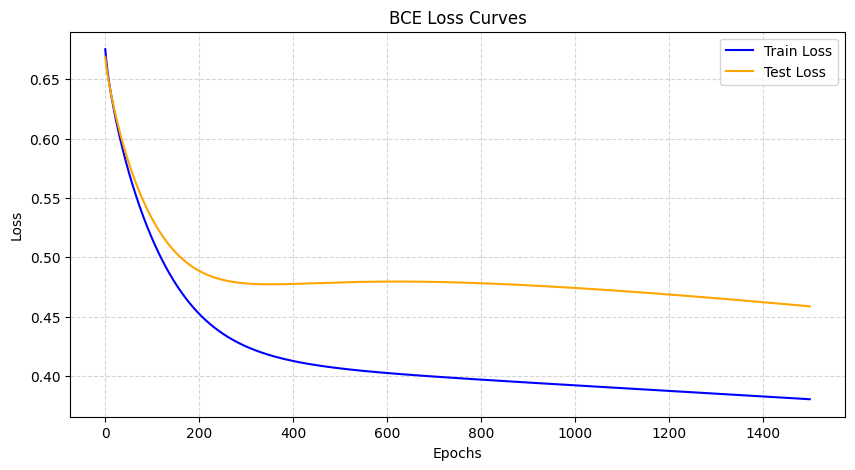

In [ ]:
# Plot Training & Validation Loss curves
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss', color='blue')
plt.plot(test_losses, label='Test Loss', color='orange')
plt.title('BCE Loss Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# 7. Evaluation metrics
Now, we evaluate the performance of our customized ANN on the test set using standard binary classification metrics: Confusion Matrix, ROC curve, and Precision-Recall curve.

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.79      0.81       100
           1       0.64      0.70      0.67        54

    accuracy                           0.76       154
   macro avg       0.74      0.75      0.74       154
weighted avg       0.77      0.76      0.76       154



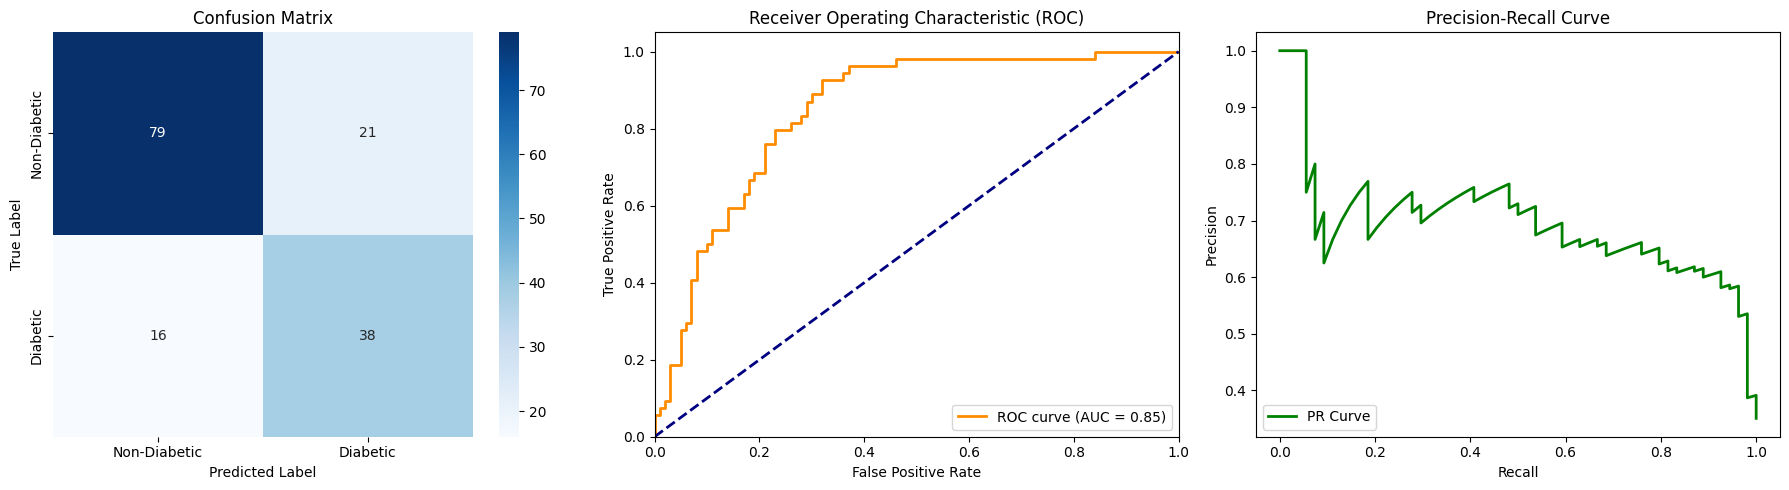

Model Execution & Evaluation completed successfully. Overall test accuracy: 75.97%


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, precision_recall_curve

# Final predictions
y_pred_prob = ann.forward(X_test)
y_pred_class = (y_pred_prob >= 0.5).astype(int)

# Detailed Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred_class))

# Plot ROC & PR Curves with Confusion Matrix side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_class)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Non-Diabetic', 'Diabetic'],
            yticklabels=['Non-Diabetic', 'Diabetic'])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")

# 3. Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_pred_prob)
axes[2].plot(recall, precision, color='green', lw=2, label='PR Curve')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].set_title('Precision-Recall Curve')
axes[2].legend(loc="lower left")

plt.tight_layout()
plt.show()

print(f"Model Execution & Evaluation completed successfully. Overall test accuracy: {np.mean(y_pred_class == y_test) * 100:.2f}%")